# Credit Scoring Capstone
## Notebook 04 — Financial Analysis

This notebook translates the calibrated Probability of Default (PD) estimates
from the credit-scoring framework into financial risk measures.

### Objectives

- Load the final calibrated PD estimates
- Define Exposure at Default (EAD) using an available exposure proxy
- Define scenario-based Loss Given Default (LGD) assumptions
- Calculate borrower-level Expected Loss (EL)
- Examine portfolio-level Expected Loss
- Evaluate the sensitivity of Expected Loss to different LGD assumptions
- Develop an illustrative risk-adjusted pricing framework

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [3]:
print(
    "Current directory:",
    Path.cwd()
)

print(
    "Final PD file exists:",
    Path(
        "../outputs/final_pd_test.csv"
    ).exists()
)

Current directory: C:\Users\USER\Downloads\SEM 5\Capstone Project I\Credit_Scoring_Capstone\notebooks
Final PD file exists: True


## 3. Load Final Probability of Default Estimates

The final test-set PD estimates produced in Notebook 03 are loaded for the
financial analysis.

The Isotonic-calibrated probability was selected as the final PD estimate
based on its held-out Brier score.

The dataset also contains `AMT_CREDIT`, which represents the credit amount
associated with each applicant and is used as an exposure proxy in the
scenario-based Expected Loss analysis.

In [5]:
financial_df = pd.read_csv(
    "../outputs/final_pd_test.csv"
)

print(
    "Financial dataset shape:",
    financial_df.shape
)

financial_df.head()

Financial dataset shape: (46127, 8)


,index,SK_ID_CURR,y_true,raw_pd,platt_pd,isotonic_pd,final_pd,AMT_CREDIT
0,61065,170816,0,0.081749,0.080934,0.102881,0.102881,221832.0
1,150133,274044,0,0.079183,0.078271,0.102881,0.102881,265851.0
2,256582,396913,0,0.205995,0.212698,0.243243,0.243243,644962.5
3,248855,387891,0,0.056039,0.054453,0.065101,0.065101,592560.0
4,144968,268100,0,0.039050,0.037267,0.017792,0.017792,238500.0


In [6]:
financial_df[
    [
        "SK_ID_CURR",
        "y_true",
        "final_pd",
        "AMT_CREDIT"
    ]
].head()

,SK_ID_CURR,y_true,final_pd,AMT_CREDIT
0,170816,0,0.102881,221832.0
1,274044,0,0.102881,265851.0
2,396913,0,0.243243,644962.5
3,387891,0,0.065101,592560.0
4,268100,0,0.017792,238500.0


In [7]:
financial_df[
    [
        "final_pd",
        "AMT_CREDIT"
    ]
].isna().sum()

final_pd      0
AMT_CREDIT    0
dtype: int64

In [8]:
financial_df[
    [
        "final_pd",
        "AMT_CREDIT"
    ]
].describe()

,final_pd,AMT_CREDIT
count,46127.000000,4.612700e+04
mean,0.080884,5.974808e+05
std,0.083813,4.007792e+05
min,0.000000,4.500000e+04
25%,0.019915,2.700000e+05
50%,0.061908,5.123385e+05
75%,0.102881,8.086500e+05
max,0.812500,3.375000e+06



## 5. Expected Loss Framework

Expected Loss (EL) represents the expected monetary loss associated with credit risk.

It is calculated using three components:

$$
EL = PD \times LGD \times EAD
$$

where:

- **PD (Probability of Default)** represents the estimated probability that the borrower defaults.
- **LGD (Loss Given Default)** represents the proportion of the exposure that would be lost if default occurs.
- **EAD (Exposure at Default)** represents the amount exposed at the time of default.

The calibrated probability produced by the credit-scoring framework is used as PD.

The Home Credit application dataset does not provide a realised LGD measure. Therefore, LGD is treated as a scenario assumption rather than an estimated borrower-level quantity.

`AMT_CREDIT` is used as an exposure proxy for EAD. Consequently, the resulting Expected Loss estimates should be interpreted as scenario-based estimates rather than realised accounting losses.


In [10]:
financial_df[
    "PD"
] = financial_df[
    "final_pd"
]

financial_df[
    "EAD_proxy"
] = financial_df[
    "AMT_CREDIT"
]

In [11]:
financial_df[
    [
        "PD",
        "EAD_proxy"
    ]
].describe()

,PD,EAD_proxy
count,46127.000000,4.612700e+04
mean,0.080884,5.974808e+05
std,0.083813,4.007792e+05
min,0.000000,4.500000e+04
25%,0.019915,2.700000e+05
50%,0.061908,5.123385e+05
75%,0.102881,8.086500e+05
max,0.812500,3.375000e+06



### PD and EAD Definition

For borrower $i$:

$$
PD_i = \text{Isotonic-calibrated model probability}
$$

and:

$$
EAD_i^{\text{proxy}} = \text{AMT\_CREDIT}_i
$$

The exposure measure is therefore an approximation based on the available application data rather than a realised exposure observed at the time of default.


## 7. LGD Scenario Assumptions

Because realised Loss Given Default is not available in the dataset, three
illustrative LGD scenarios are considered:

- 20% LGD — lower-loss scenario
- 40% LGD — moderate-loss scenario
- 60% LGD — higher-loss scenario

The purpose of these scenarios is to examine how assumptions regarding loss
severity affect Expected Loss while holding the model-estimated PD and
exposure proxy constant.

In [14]:
lgd_scenarios = {
    "LGD_20": 0.20,
    "LGD_40": 0.40,
    "LGD_60": 0.60
}

lgd_scenarios

{'LGD_20': 0.2, 'LGD_40': 0.4, 'LGD_60': 0.6}

In [15]:
for scenario, lgd in lgd_scenarios.items():

    financial_df[
        f"EL_{scenario}"
    ] = (
        financial_df["PD"]
        * lgd
        * financial_df["EAD_proxy"]
    )

In [16]:
financial_df[
    [
        "SK_ID_CURR",
        "PD",
        "EAD_proxy",
        "EL_LGD_20",
        "EL_LGD_40",
        "EL_LGD_60"
    ]
].head(10).round(2)

,SK_ID_CURR,PD,EAD_proxy,EL_LGD_20,EL_LGD_40,EL_LGD_60
0,170816,0.10,221832.0,4564.44,9128.89,13693.33
1,274044,0.10,265851.0,5470.19,10940.37,16410.56
2,396913,0.24,644962.5,31376.55,62753.11,94129.66
3,387891,0.07,592560.0,7715.27,15430.54,23145.81
4,268100,0.02,238500.0,848.68,1697.35,2546.03
5,360073,0.07,781920.0,10180.78,20361.57,30542.35
6,237928,0.12,225000.0,5329.84,10659.67,15989.51
7,371206,0.02,251091.0,893.48,1786.96,2680.44
8,258071,0.02,834048.0,2967.87,5935.74,8903.61
9,340351,0.15,385164.0,11566.49,23132.97,34699.46


In [17]:
el_summary = []

for scenario, lgd in lgd_scenarios.items():

    el_column = f"EL_{scenario}"

    el_summary.append({
        "LGD_Scenario": scenario,
        "LGD": lgd,

        "Mean_EL":
            financial_df[
                el_column
            ].mean(),

        "Median_EL":
            financial_df[
                el_column
            ].median(),

        "Total_EL":
            financial_df[
                el_column
            ].sum()
    })

el_summary = pd.DataFrame(
    el_summary
)

el_summary

,LGD_Scenario,LGD,Mean_EL,Median_EL,Total_EL
0,LGD_20,0.2,9013.825901,5366.156682,4.157807e+08
1,LGD_40,0.4,18027.651801,10732.313364,8.315615e+08
2,LGD_60,0.6,27041.477702,16098.470046,1.247342e+09


In [18]:
el_summary.round(2)

,LGD_Scenario,LGD,Mean_EL,Median_EL,Total_EL
0,LGD_20,0.2,9013.83,5366.16,4.157807e+08
1,LGD_40,0.4,18027.65,10732.31,8.315615e+08
2,LGD_60,0.6,27041.48,16098.47,1.247342e+09


In [19]:
financial_df.to_csv(
    "../outputs/financial_analysis.csv",
    index=False
)

el_summary.to_csv(
    "../outputs/expected_loss_summary.csv",
    index=False
)

print(
    "Financial analysis saved:",
    financial_df.shape
)

print(
    "Expected Loss summary saved:",
    el_summary.shape
)

Financial analysis saved: (46127, 13)
Expected Loss summary saved: (3, 5)


## 11. Expected Loss Scenario Analysis

The Expected Loss estimates are compared across the three LGD scenarios.

Because PD and the exposure proxy remain unchanged, differences in Expected
Loss are driven by the assumed LGD. This provides a simple sensitivity
analysis showing how loss-severity assumptions affect borrower-level and
portfolio-level credit-risk estimates.

In [21]:
el_summary.round(2)

,LGD_Scenario,LGD,Mean_EL,Median_EL,Total_EL
0,LGD_20,0.2,9013.83,5366.16,4.157807e+08
1,LGD_40,0.4,18027.65,10732.31,8.315615e+08
2,LGD_60,0.6,27041.48,16098.47,1.247342e+09


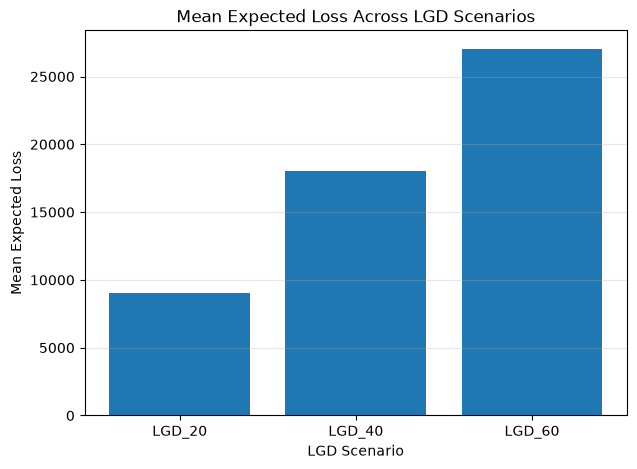

In [22]:
plt.figure(figsize=(7, 5))

plt.bar(
    el_summary["LGD_Scenario"],
    el_summary["Mean_EL"]
)

plt.xlabel("LGD Scenario")
plt.ylabel("Mean Expected Loss")
plt.title("Mean Expected Loss Across LGD Scenarios")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.savefig(
    "../outputs/figures/mean_expected_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

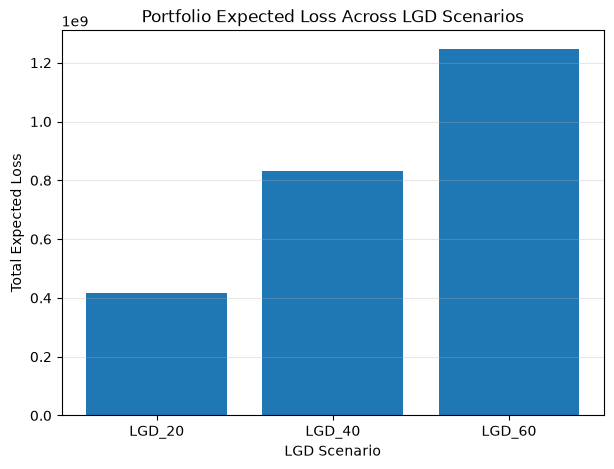

In [23]:
plt.figure(figsize=(7, 5))

plt.bar(
    el_summary["LGD_Scenario"],
    el_summary["Total_EL"]
)

plt.xlabel("LGD Scenario")
plt.ylabel("Total Expected Loss")
plt.title("Portfolio Expected Loss Across LGD Scenarios")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.savefig(
    "../outputs/figures/total_expected_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Expected Loss Sensitivity

Expected Loss increases proportionally as the assumed LGD increases.

The 40% LGD scenario produces approximately twice the Expected Loss of the
20% scenario, while the 60% scenario produces approximately three times the
Expected Loss.

This relationship follows directly from the Expected Loss equation because
PD and the exposure proxy are held constant while LGD changes.

The analysis therefore demonstrates the sensitivity of financial loss
estimates to assumptions regarding loss severity.


## 12. Indicative Risk-Adjusted Pricing

A simplified pricing framework is developed to demonstrate how estimated credit risk could be incorporated into an indicative lending rate.

The framework is:

$$
R_i =
R_{\text{base}}
+
\frac{EL_i}{EAD_i}
+
C_{\text{operational}}
+
M_{\text{profit}}
$$

where:

- $R_i$ is the indicative rate for borrower $i$.
- $R_{\text{base}}$ represents a base funding or risk-free component.
- $EL_i/EAD_i$ represents the expected credit-loss rate.
- $C_{\text{operational}}$ represents an illustrative operational-cost component.
- $M_{\text{profit}}$ represents an illustrative profit-margin component.

Because:

$$
EL_i = PD_i \times LGD \times EAD_i
$$

the pricing equation can be simplified to:

$$
R_i =
R_{\text{base}}
+
(PD_i \times LGD)
+
C_{\text{operational}}
+
M_{\text{profit}}
$$

The resulting rates are illustrative scenario outputs and should not be interpreted as actual lending offers or recommended commercial prices.


## 13. Pricing Assumptions

The pricing analysis uses illustrative assumptions rather than observed
commercial lending costs:

- Base rate: 4%
- Operational cost component: 2%
- Profit margin: 3%

The combined fixed component is therefore 9%.

These assumptions are used only to demonstrate how model-estimated PD can
flow through a simplified risk-adjusted pricing framework.

In [27]:
base_rate = 0.04
operational_cost = 0.02
profit_margin = 0.03

fixed_rate = (
    base_rate
    + operational_cost
    + profit_margin
)

print(
    "Fixed rate component:",
    f"{fixed_rate:.2%}"
)

Fixed rate component: 9.00%


In [28]:
for scenario, lgd in lgd_scenarios.items():

    financial_df[
        f"Rate_{scenario}"
    ] = (
        fixed_rate
        + financial_df["PD"] * lgd
    )

In [29]:
financial_df[
    [
        "SK_ID_CURR",
        "PD",
        "Rate_LGD_20",
        "Rate_LGD_40",
        "Rate_LGD_60"
    ]
].head(10).round(4)

,SK_ID_CURR,PD,Rate_LGD_20,Rate_LGD_40,Rate_LGD_60
0,170816,0.1029,0.1106,0.1312,0.1517
1,274044,0.1029,0.1106,0.1312,0.1517
2,396913,0.2432,0.1386,0.1873,0.2359
3,387891,0.0651,0.1030,0.1160,0.1291
4,268100,0.0178,0.0936,0.0971,0.1007
5,360073,0.0651,0.1030,0.1160,0.1291
6,237928,0.1184,0.1137,0.1374,0.1611
7,371206,0.0178,0.0936,0.0971,0.1007
8,258071,0.0178,0.0936,0.0971,0.1007
9,340351,0.1502,0.1200,0.1501,0.1801


In [30]:
pricing_preview = financial_df[
    [
        "SK_ID_CURR",
        "PD",
        "Rate_LGD_20",
        "Rate_LGD_40",
        "Rate_LGD_60"
    ]
].copy()

pricing_preview[
    [
        "Rate_LGD_20",
        "Rate_LGD_40",
        "Rate_LGD_60"
    ]
] *= 100

pricing_preview.head(10).round(2)

,SK_ID_CURR,PD,Rate_LGD_20,Rate_LGD_40,Rate_LGD_60
0,170816,0.10,11.06,13.12,15.17
1,274044,0.10,11.06,13.12,15.17
2,396913,0.24,13.86,18.73,23.59
3,387891,0.07,10.30,11.60,12.91
4,268100,0.02,9.36,9.71,10.07
5,360073,0.07,10.30,11.60,12.91
6,237928,0.12,11.37,13.74,16.11
7,371206,0.02,9.36,9.71,10.07
8,258071,0.02,9.36,9.71,10.07
9,340351,0.15,12.00,15.01,18.01



### Relationship Between PD and Indicative Pricing

Under the simplified pricing framework, borrowers with higher estimated PD receive a larger expected-loss component.

For a fixed LGD:

$$
PD \uparrow
\Rightarrow
PD \times LGD \uparrow
\Rightarrow
R \uparrow
$$

The pricing analysis therefore demonstrates how differences in calibrated default-risk estimates can propagate into downstream financial decisions.

The framework is illustrative and does not represent the full set of variables or constraints used in real-world loan pricing.


In [32]:
rate_columns = [
    "Rate_LGD_20",
    "Rate_LGD_40",
    "Rate_LGD_60"
]

rate_summary = (
    financial_df[
        rate_columns
    ]
    .describe()
    * 100
)

rate_summary.round(2)

,Rate_LGD_20,Rate_LGD_40,Rate_LGD_60
count,4612700.00,4612700.00,4612700.00
mean,10.62,12.24,13.85
std,1.68,3.35,5.03
min,9.00,9.00,9.00
25%,9.40,9.80,10.19
50%,10.24,11.48,12.71
75%,11.06,13.12,15.17
max,25.25,41.50,57.75



## 17. PD and Indicative Rate Relationship

The relationship between Probability of Default and the indicative risk-adjusted rate is visualised under each LGD scenario.

Because the simplified pricing equation is:

$$
R_i = R_{\text{fixed}} + PD_i \times LGD
$$

the indicative rate increases linearly with PD.

Higher LGD assumptions produce a steeper relationship because a given Probability of Default corresponds to a larger expected-loss component.


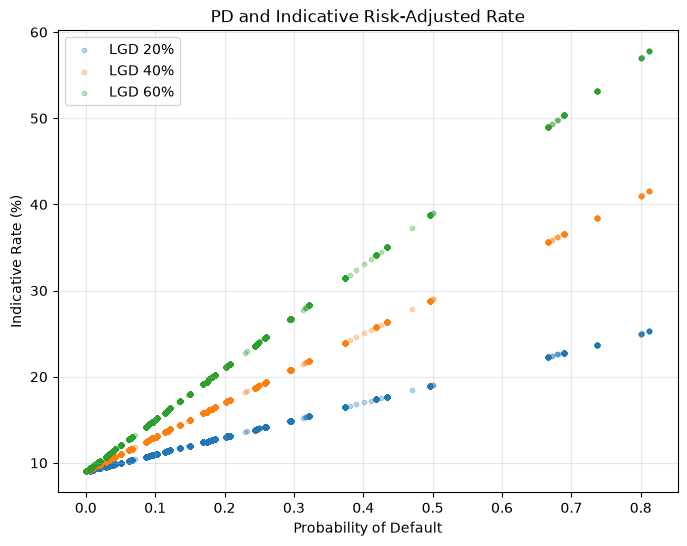

In [34]:
plt.figure(figsize=(8, 6))

plt.scatter(
    financial_df["PD"],
    financial_df["Rate_LGD_20"] * 100,
    alpha=0.3,
    s=10,
    label="LGD 20%"
)

plt.scatter(
    financial_df["PD"],
    financial_df["Rate_LGD_40"] * 100,
    alpha=0.3,
    s=10,
    label="LGD 40%"
)

plt.scatter(
    financial_df["PD"],
    financial_df["Rate_LGD_60"] * 100,
    alpha=0.3,
    s=10,
    label="LGD 60%"
)

plt.xlabel("Probability of Default")
plt.ylabel("Indicative Rate (%)")
plt.title("PD and Indicative Risk-Adjusted Rate")

plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    "../outputs/figures/pd_vs_indicative_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 18. Distribution of Borrower-Level Expected Loss

The distribution of borrower-level Expected Loss is examined using the 40% LGD scenario as an illustrative middle scenario.

Unlike the simplified risk-adjusted rate, borrower-level Expected Loss is affected by both Probability of Default and the exposure proxy:

$$
EL_i = PD_i \times LGD \times EAD_i
$$

Therefore, two borrowers with the same PD can have different Expected Loss if their credit exposures differ.


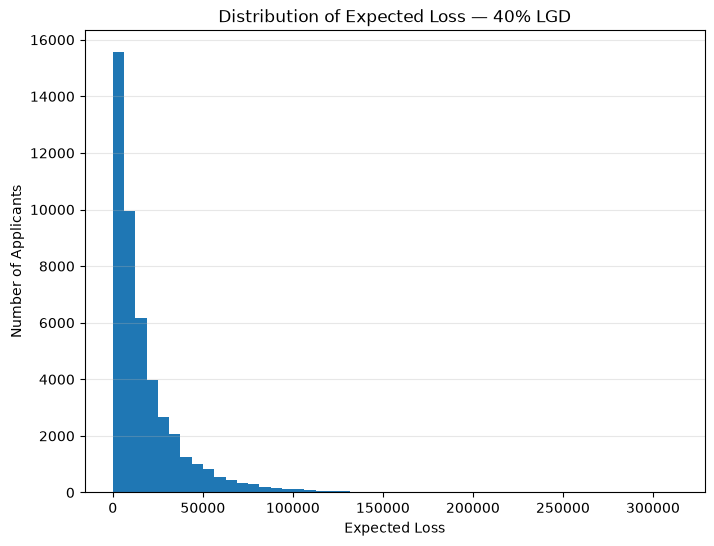

In [36]:
plt.figure(figsize=(8, 6))

plt.hist(
    financial_df["EL_LGD_40"],
    bins=50
)

plt.xlabel("Expected Loss")
plt.ylabel("Number of Applicants")
plt.title("Distribution of Expected Loss — 40% LGD")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.savefig(
    "../outputs/figures/expected_loss_distribution_lgd40.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
borrower_examples = financial_df.sort_values(
    "PD"
).iloc[
    [
        0,
        len(financial_df) // 2,
        -1
    ]
]

borrower_examples[
    [
        "SK_ID_CURR",
        "PD",
        "EAD_proxy",
        "EL_LGD_40",
        "Rate_LGD_40"
    ]
].round(4)

,SK_ID_CURR,PD,EAD_proxy,EL_LGD_40,Rate_LGD_40
26859,228430,0.0000,247500.0,0.0000,0.0900
20851,302865,0.0619,390447.0,9668.6812,0.1148
29471,310987,0.8125,640080.0,208026.0000,0.4150


## 19. Illustrative Borrower Comparison

Borrowers with different estimated default probabilities can be compared to
demonstrate how model outputs propagate into financial quantities.

Under a common LGD assumption, a higher PD increases both the expected-loss
component and the indicative risk-adjusted rate.

Expected Loss additionally depends on exposure. Therefore, a borrower with a
lower PD but substantially larger exposure may still generate a larger
monetary Expected Loss than a borrower with a higher PD but smaller exposure.

## 20. Supplementary Financial Consistency Checks

This non-destructive quality-assurance section checks that the final PDs are valid probabilities, the exposure proxy is non-negative, and the expected-loss and indicative-rate calculations agree with the stated formulas for each LGD scenario. It also verifies that increasing LGD cannot decrease expected loss or the indicative rate for a fixed borrower. These checks do not modify the financial assumptions or fitted models.

In [40]:
# Independent arithmetic checks for the illustrative financial calculations.
financial_checks = {
    "PD within [0, 1]": financial_df["PD"].between(0, 1).all(),
    "PD has no missing values": financial_df["PD"].notna().all(),
    "Exposure proxy is non-negative": financial_df["EAD_proxy"].ge(0).all(),
    "Exposure proxy has no missing values": financial_df["EAD_proxy"].notna().all(),
}

for scenario, lgd in lgd_scenarios.items():
    financial_checks[f"Expected loss formula: {scenario}"] = np.allclose(
        financial_df[f"EL_{scenario}"],
        financial_df["PD"] * lgd * financial_df["EAD_proxy"],
        equal_nan=False,
    )
    financial_checks[f"Indicative rate formula: {scenario}"] = np.allclose(
        financial_df[f"Rate_{scenario}"],
        fixed_rate + financial_df["PD"] * lgd,
        equal_nan=False,
    )

financial_checks["EL rises with LGD"] = (
    (financial_df["EL_LGD_20"] <= financial_df["EL_LGD_40"]).all()
    and (financial_df["EL_LGD_40"] <= financial_df["EL_LGD_60"]).all()
)
financial_checks["Indicative rate rises with LGD"] = (
    (financial_df["Rate_LGD_20"] <= financial_df["Rate_LGD_40"]).all()
    and (financial_df["Rate_LGD_40"] <= financial_df["Rate_LGD_60"]).all()
)

financial_check_results = pd.DataFrame.from_dict(
    financial_checks, orient="index", columns=["Passed"]
)
display(financial_check_results)
assert all(financial_checks.values()), "Financial consistency checks failed."
print("All financial consistency checks passed.")

,Passed
"PD within [0, 1]",True
PD has no missing values,True
Exposure proxy is non-negative,True
Exposure proxy has no missing values,True
Expected loss formula: LGD_20,True
Indicative rate formula: LGD_20,True
Expected loss formula: LGD_40,True
Indicative rate formula: LGD_40,True
Expected loss formula: LGD_60,True
Indicative rate formula: LGD_60,True


All financial consistency checks passed.


In [41]:
financial_df.to_csv(
    "../outputs/financial_analysis.csv",
    index=False
)

el_summary.to_csv(
    "../outputs/expected_loss_summary.csv",
    index=False
)

rate_summary.to_csv(
    "../outputs/indicative_rate_summary.csv"
)

print("Final financial outputs saved.")
print("Financial dataset:", financial_df.shape)
print("Expected Loss summary:", el_summary.shape)
print("Rate summary:", rate_summary.shape)

Final financial outputs saved.
Financial dataset: (46127, 16)
Expected Loss summary: (3, 5)
Rate summary: (8, 3)



## 21. Conclusion

This notebook translated the calibrated Probability of Default estimates into scenario-based financial risk measures.

Borrower-level Expected Loss was calculated using:

$$
EL = PD \times LGD \times EAD
$$

where the Isotonic-calibrated probability was used as PD, `AMT_CREDIT` was used as an exposure proxy, and LGD values of 20%, 40%, and 60% were considered as illustrative scenarios.

The scenario analysis demonstrated that Expected Loss increases proportionally with the assumed LGD. Borrower-level monetary Expected Loss also varies according to both estimated default risk and credit exposure.

A simplified indicative risk-adjusted pricing framework was subsequently constructed:

$$
R = R_{\text{base}} + PD \times LGD + C_{\text{operational}} + M_{\text{profit}}
$$

In the implemented scenario analysis, the fixed rate component was set to 9%, with no additional operational-cost or profit-margin components applied separately. Therefore, the implemented equation was:

$$
R = 0.09 + PD \times LGD
$$

The resulting rates demonstrate how differences in model-estimated credit risk can propagate into downstream financial quantities. These outputs are illustrative scenario estimates and should not be interpreted as actual lending offers or commercial pricing recommendations.
